# Blended RAG — Eval Results Visualisation

Compares baseline (BM25 + KNN) vs full pipeline (BM25 + KNN + SPLADE) across query types.

In [4]:
import json
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

RESULTS_DIR = Path('../results')
DOCS_DIR    = Path('../docs')

baseline = json.loads((RESULTS_DIR / 'eval_baseline_best_fields.json').read_text())
splade   = json.loads((RESULTS_DIR / 'eval_results.json').read_text())

print('Loaded eval results')
print(f'Baseline overall: doc_recall={baseline["overall"]["doc_recall@k"]:.3f}  mrr={baseline["overall"]["mrr"]:.3f}')
print(f'SPLADE   overall: doc_recall={splade["overall"]["doc_recall@k"]:.3f}  mrr={splade["overall"]["mrr"]:.3f}')

Loaded eval results
Baseline overall: doc_recall=0.875  mrr=0.735
SPLADE   overall: doc_recall=0.925  mrr=0.765


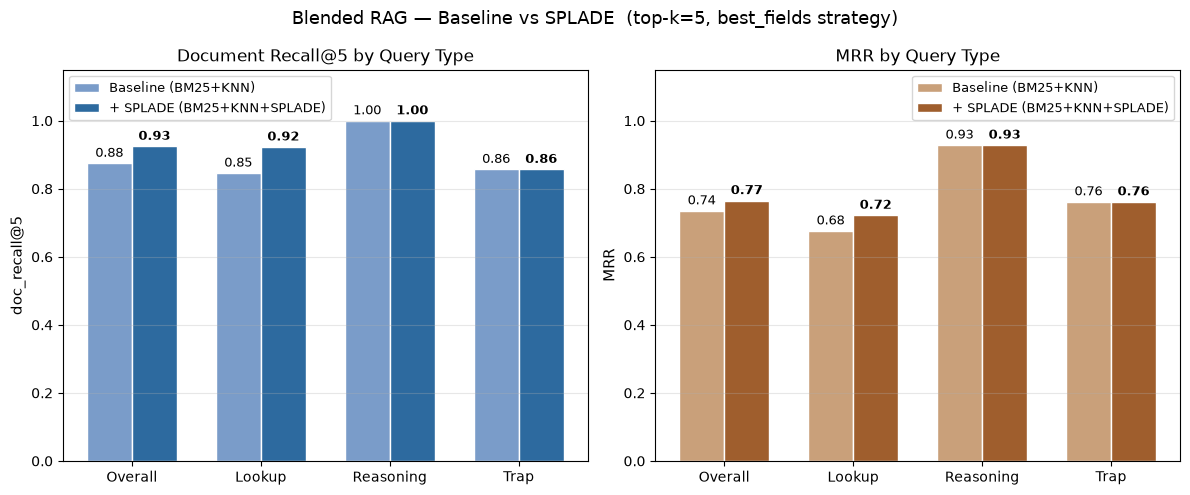

Saved to ../docs/eval_comparison.png


In [5]:
query_types = ['overall', 'lookup', 'reasoning', 'trap']
labels = ['Overall', 'Lookup', 'Reasoning', 'Trap']

def get_metric(data, qtype, metric):
    section = data['overall'] if qtype == 'overall' else data['by_type'][qtype]
    return section[metric]

recall_baseline = [get_metric(baseline, qt, 'doc_recall@k') for qt in query_types]
recall_splade = [get_metric(splade,   qt, 'doc_recall@k') for qt in query_types]
mrr_baseline = [get_metric(baseline, qt, 'mrr') for qt in query_types]
mrr_splade = [get_metric(splade,   qt, 'mrr') for qt in query_types]

x = np.arange(len(labels))
w = 0.35

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# doc_recall
ax = axes[0]
bars1 = ax.bar(x - w/2, recall_baseline, w, label='Baseline (BM25+KNN)',       color='#7a9cc9', edgecolor='white')
bars2 = ax.bar(x + w/2, recall_splade,   w, label='+ SPLADE (BM25+KNN+SPLADE)', color='#2d6a9f', edgecolor='white')
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
    
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.15)
ax.set_ylabel('doc_recall@5', fontsize=11)
ax.set_title('Document Recall@5 by Query Type', fontsize=12)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

# MRR
ax = axes[1]
bars1 = ax.bar(x - w/2, mrr_baseline, w, label='Baseline (BM25+KNN)',        color='#c9a07a', edgecolor='white')
bars2 = ax.bar(x + w/2, mrr_splade,   w, label='+ SPLADE (BM25+KNN+SPLADE)', color='#9f5e2d', edgecolor='white')
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9)

for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01, f'{bar.get_height():.2f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1.15)
ax.set_ylabel('MRR', fontsize=11)
ax.set_title('MRR by Query Type', fontsize=12)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

plt.suptitle('Blended RAG — Baseline vs SPLADE  (top-k=5, best_fields strategy)', fontsize=13)
plt.tight_layout()

out = DOCS_DIR / 'eval_comparison.png'
plt.savefig(out, dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved to {out}')